# 05 — Resource scaling, blocking, and site-dependent MPUs

Building the circuit is only feasible for moderate $N$. `synthesis_cost_params()` measures the cost of every building block **once**. `UniformMPU.analytic_synthesis_stats(params, N)` then rebuilds the synthesis tree for any $N$ from those blocks and schedules it exactly, without building the circuit: the numbers equal those of the circuit `synthesize()` would return. Each tree layer multiplies the depth by $2\ell+1$, so

$$\text{depth}(N)\propto N^{\log_2(2\ell+1)}.$$

In [1]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import matplotlib.pyplot as plt

# Categorical colours (fixed order) and neutral ink for text and axes.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.edgecolor": INK_2,
        "axes.labelcolor": INK,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2,
        "lines.markersize": 6,
        "legend.frameon": False,
    }
)

import numpy as np

from mpu_generators import build_family
from TreeMPU import UniformMPU

In [2]:
t, l, r = build_family("branching_uniform", d=2, bond_dim=2, seed=0)
Ns = [2**k for k in range(1, 11)]
curves = {}
for label, options in [
    ("canonical", dict(boundary_sigma_tau=False)),
    ("q = chi (qD)", dict(boundary_opt_k=1)),
]:
    m = UniformMPU(A=t[0], l_vec=l, r_vec=r, N=8, light=True, **options)
    params = m.synthesis_cost_params()
    depth = [UniformMPU.analytic_synthesis_stats(params, N)["depth"] for N in Ns]
    curves[label] = (m.q_unif, m.ell, depth)
    ratio = depth[-1] / depth[-2]
    print(
        f"{label:14s} q = {m.q_unif:.4f}  ell = {m.ell}  depth(2N)/depth(N) -> {ratio:.3f}  (2*ell+1 = {2 * m.ell + 1})"
    )

canonical      q = 2.0641  ell = 2  depth(2N)/depth(N) -> 5.000  (2*ell+1 = 5)


q = chi (qD)   q = 2.0000  ell = 1  depth(2N)/depth(N) -> 3.017  (2*ell+1 = 3)


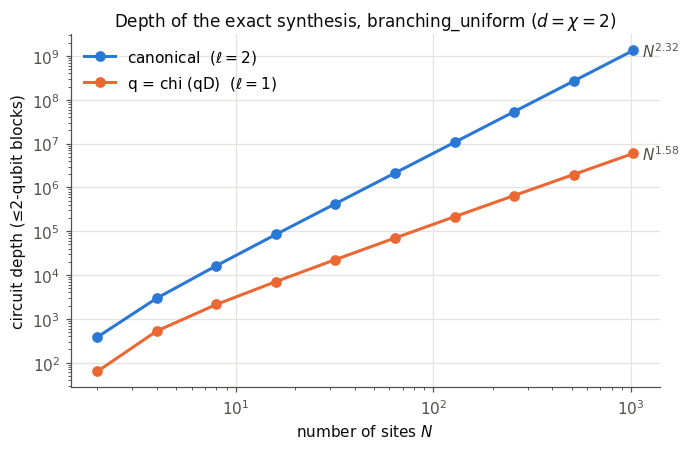

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for color, (label, (_q, ell, depth)) in zip(SERIES, curves.items()):
    ax.loglog(Ns, depth, "o-", color=color, label=f"{label}  ($\\ell={ell}$)")
    ax.annotate(
        f"$N^{{{np.log2(2 * ell + 1):.2f}}}$",
        (Ns[-1], depth[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=INK_2,
    )
ax.set_xlabel("number of sites $N$")
ax.set_ylabel("circuit depth (≤2-qubit blocks)")
ax.set_title(
    "Depth of the exact synthesis, branching_uniform ($d=\\chi=2$)", color=INK, fontsize=11
)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

Reaching $q=2$ lowers $\ell$ from 2 to 1 and the depth exponent from $\log_2 5\approx2.32$ to $\log_2 3\approx1.58$.

## Blocking

Blocking $m$ sites into one raises the local dimension to $d^m$ and keeps $\chi$ fixed. This can restore Assumption 1 and changes $q$ and the per-merge cost. `block_mpu_tensors` performs the contraction (the first site of each block is the most significant digit, the opposite of the dense and Qiskit convention, so the two operators agree only after swapping the digits inside each block).

In [4]:
from TreeMPU import block_mpu_tensors, dense_unitary_from_tensors

t8, l8, r8 = build_family("branching_uniform", d=2, bond_dim=2, seed=0, n_sites=4)
blocked = block_mpu_tensors(t8, 2)
print(
    "original:",
    len(t8),
    "sites of shape",
    t8[0].shape,
    "| blocked:",
    len(blocked),
    "sites of shape",
    blocked[0].shape,
)

U = dense_unitary_from_tensors(t8, l8, r8)
U_blocked = dense_unitary_from_tensors(blocked, l8, r8)

# Site 0 is the least significant digit of U, but inside a block the first
# site is the most significant one: swap the two digits of every block.
n, d = len(t8), 2
digits = np.indices((d,) * n).reshape(n, -1)[::-1]  # digits[k] = digit of site k
swapped = digits.reshape(n // 2, 2, -1)[:, ::-1].reshape(n, -1)
perm = (swapped * d ** np.arange(n)[:, None]).sum(0)
print("equal as stored:", np.allclose(U, U_blocked))
print(
    "equal after swapping the digits in each block:", np.allclose(U, U_blocked[np.ix_(perm, perm)])
)

original: 4 sites of shape (2, 2, 2, 2) | blocked: 2 sites of shape (4, 4, 2, 2)
equal as stored: False
equal after swapping the digits in each block: True


## Site-dependent MPUs: `GeneralMPU`

For a chain with different tensors on every site, `GeneralMPU` brings the chain to canonical form (minimal bond dimensions, $L_k=\mathbb 1$, $R_k=\mathrm{diag}(s)$). It then computes one conditioning number per bond; the relevant value is $q=\max_k q_k$ (thesis `eq:q_nonuniform`).

In [5]:
from TreeMPU import GeneralMPU, phase_aligned_error, reconstruct_circuit_unitary

t, l, r = build_family("branching_general", d=2, bond_dim=2, seed=0, n_sites=3)
g = GeneralMPU(tensors_A=t, l_vec=l, r_vec=r)
print("bond sources:", g.boundary_source, "| q =", round(g.q, 6))
qc, sys_regs, *_ = g.synthesize()
U_rec, leak = reconstruct_circuit_unitary(qc, sys_regs)
print(
    f"{qc.num_qubits} qubits | error = {phase_aligned_error(U_rec, dense_unitary_from_tensors(t, l, r)):.1e} | leakage = {leak:.1e}"
)

bond sources: ['canonical', 'canonical'] | q = 2.142347


17 qubits | error = 1.2e-14 | leakage = 2.8e-14
